# Customer Churn Prediction and Retention Strategy Analysis

## Business Problem
Customer churn reduces revenue and increases the cost of acquiring new customers. This project aims to identify the factors associated with churn and build a predictive model to classify customers who are at risk of leaving.

## Research Question
What factors contribute most to customer churn, and how accurately can a predictive model identify customers who are likely to leave?

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

### Load and Inspect the Data

In [3]:
df = pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
#Checking the size of the dataset

df.shape

(7043, 21)

In [5]:
#inspects the columns
df.columns.tolist()

['customerID',
 'gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'tenure',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'MonthlyCharges',
 'TotalCharges',
 'Churn']

In [6]:
#checks data types and missing values

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [7]:
#checking on missing values more clearly

df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [8]:
#checks if there is any hidden missing value

(df == " ").sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [9]:
#checks for duplicates
df.duplicated().sum()

0

### Cleaning the Data

In [10]:
# Removes the customer ID column
# because customerID is only an identifier. It does not help predict churn.

df = df.drop(columns=["customerID"], errors="ignore")

In [11]:
# Cleans the TotalCharges column
# the column looks numeric, but it is stored as numeric, so this converts text to numeric and 
# any bad or blank value becomes NaN

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

In [12]:
# checking missing value again

df.isnull().sum()

gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [13]:
# Filling missing values
# Median is a safe choice because it is less affected by extreme values.

df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())

In [14]:
# Converting the target column(Churn)
# The churn column is text: Yes and No, so it needs to be converted to numbers
# Machine learning models need numerical target values.

df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

In [15]:
# confirming the cleaned data

df.info()
df.head()
df["Churn"].value_counts()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod     7043 non-null   object 


Churn
0    5174
1    1869
Name: count, dtype: int64

### Exploratory Data Analysis

In [16]:
#Summary statistics
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn
count,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2281.916928,0.265370
std,0.368612,24.559481,30.090047,2265.270398,0.441561
min,0.000000,0.000000,18.250000,18.800000,0.000000
25%,0.000000,9.000000,35.500000,402.225000,0.000000
50%,0.000000,29.000000,70.350000,1397.475000,0.000000
75%,0.000000,55.000000,89.850000,3786.600000,1.000000
max,1.000000,72.000000,118.750000,8684.800000,1.000000


In [17]:
# Overall churn rate

churn_rate = df["Churn"].mean() * 100
print(f"Churn rate: {churn_rate:.2f}%")

Churn rate: 26.54%


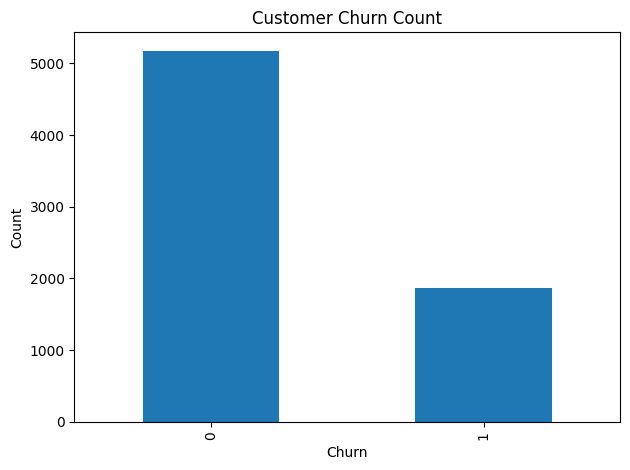

In [62]:
# churn count chart

plt.figure()
df["Churn"].value_counts().plot(kind="bar")
plt.title("Customer Churn Count")
plt.xlabel("Churn")
plt.ylabel("Count")
plt.tight_layout()
plt.savefig("../outputs/charts/churn_count.png")
plt.show()

In [23]:
# Analyzes churn by contract type

contract_churn = pd.crosstab(df["Contract"], df["Churn"], normalize="index") * 100
contract_churn


Churn,0,1
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


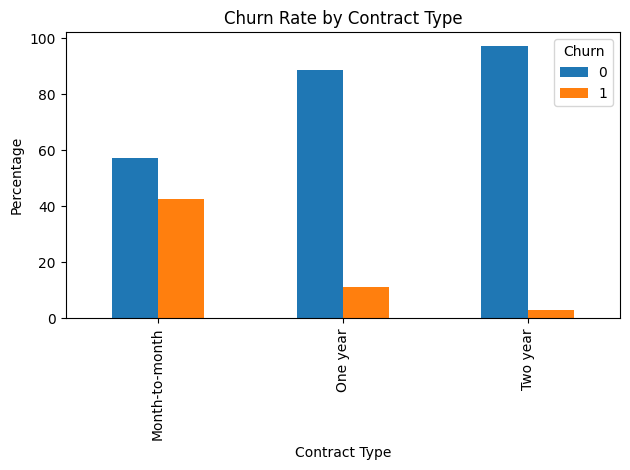

In [63]:
# plots churn by contract type

contract_churn.plot(kind="bar")
plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Percentage")
plt.tight_layout()
plt.savefig("../outputs/charts/churn_contracttype.png")
plt.show()


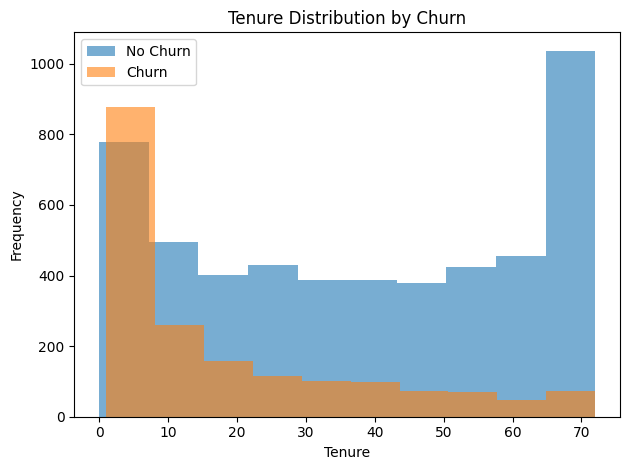

In [64]:
# churn rate by tenure

plt.hist(df[df["Churn"] == 0]["tenure"], alpha=0.6, label="No Churn")
plt.hist(df[df["Churn"] == 1]["tenure"], alpha=0.6, label="Churn")
plt.title("Tenure Distribution by Churn")
plt.xlabel("Tenure")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.savefig("../outputs/charts/churn_tenure.png")
plt.show()

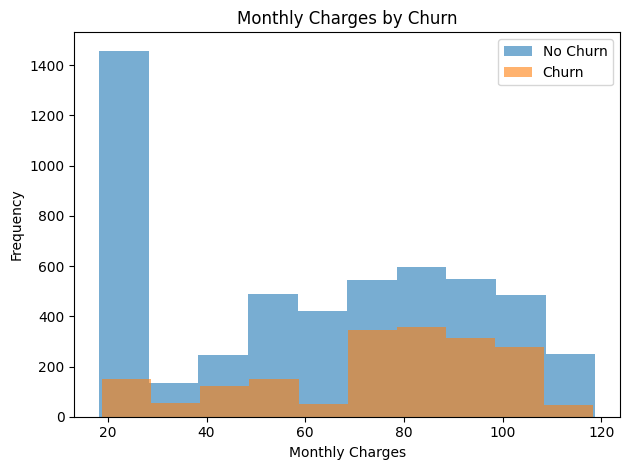

In [65]:
# Analyzes churn by monthly charges

plt.hist(df[df["Churn"] == 0]["MonthlyCharges"], alpha=0.6, label="No Churn")
plt.hist(df[df["Churn"] == 1]["MonthlyCharges"], alpha=0.6, label="Churn")
plt.title("Monthly Charges by Churn")
plt.xlabel("Monthly Charges")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.savefig("../outputs/charts/churn_monthlychareges.png")
plt.show()

In [28]:
# Analyzes churn by payment method

payment_churn = pd.crosstab(df["PaymentMethod"], df["Churn"], normalize="index") * 100
payment_churn

Churn,0,1
PaymentMethod,,
Bank transfer (automatic),83.290155,16.709845
Credit card (automatic),84.756899,15.243101
Electronic check,54.714588,45.285412
Mailed check,80.893300,19.106700


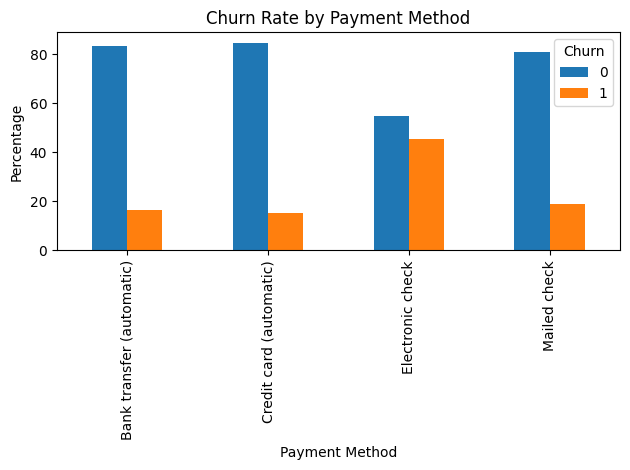

In [66]:
# plots churn by payment mathod

payment_churn.plot(kind="bar")
plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Percentage")
plt.tight_layout()
plt.savefig("../outputs/charts/churn_paymentmethod.png")
plt.show()

In [30]:
# Analyzes churn by internet service

internet_churn = pd.crosstab(df["InternetService"], df["Churn"], normalize="index") * 100
internet_churn

Churn,0,1
InternetService,,
DSL,81.040892,18.959108
Fiber optic,58.107235,41.892765
No,92.595020,7.404980


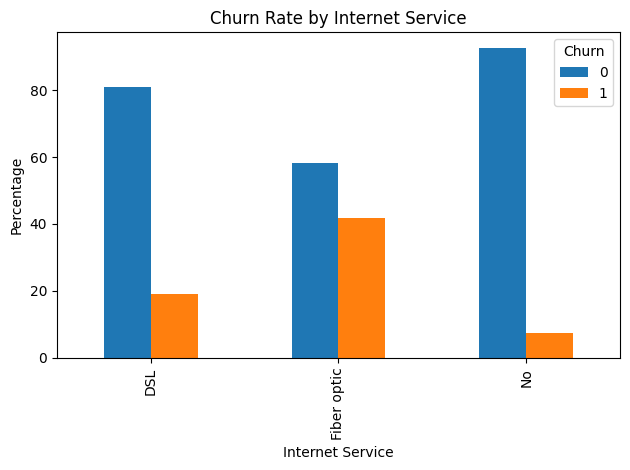

In [67]:
# plots churn by internet service

internet_churn.plot(kind="bar")
plt.title("Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Percentage")
plt.tight_layout()
plt.savefig("../outputs/charts/churn_internateservice.png")
plt.show()

In [34]:
#creates tenure group

df["tenure_group"] = pd.cut(
    df["tenure"],
    bins=[0, 12, 24, 48, 72],
    labels=["0-12 Months", "13-24 Months", "25-48 Months", "49-72 Months"]
)

In [36]:
# calculates churn by tenure group

tenure_group_churn = pd.crosstab(df["tenure_group"], df["Churn"], normalize="index") * 100
tenure_group_churn

Churn,0,1
tenure_group,,
0-12 Months,52.321839,47.678161
13-24 Months,71.289062,28.710938
25-48 Months,79.611041,20.388959
49-72 Months,90.486824,9.513176


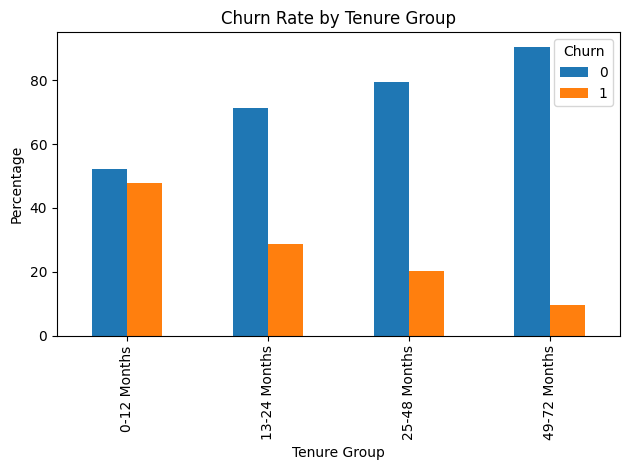

In [38]:
# plots churn by tenure group

tenure_group_churn.plot(kind="bar")
plt.title("Churn Rate by Tenure Group")
plt.xlabel("Tenure Group")
plt.ylabel("Percentage")
plt.tight_layout()
plt.show()

### Preparing Data for Modeling

In [39]:
# separates features and target

X = df.drop(columns=["Churn"])
y = df["Churn"]

In [40]:
# Converts categorical columns into numeric form

X_encoded = pd.get_dummies(X, drop_first=True)

In [43]:
# checks encoded data

X_encoded.head()
X_encoded.shape

(7043, 33)

In [44]:
# splits into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42, stratify=y
)

### Trains Models

In [45]:
# Trains Logistic Regression

lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train, y_train)
lr_preds = lr_model.predict(X_test)

In [47]:
# Trains Random Forest

rf_model = RandomForestClassifier(n_estimators=200, random_state=42)
rf_model.fit(X_train, y_train)
rf_preds = rf_model.predict(X_test)

### Evaluates Models

In [49]:
# creates evaluation function

def evaluate_model(y_true, y_pred, model_name):
    print(f"\n{model_name}")
    print("-" * 40)
    print("Accuracy:", accuracy_score(y_true, y_pred))
    print("Precision:", precision_score(y_true, y_pred))
    print("Recall:", recall_score(y_true, y_pred))
    print("F1 Score:", f1_score(y_true, y_pred))
    print("\nConfusion Matrix:")
    print(confusion_matrix(y_true, y_pred))
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred))

In [50]:
# Evaluates Logistic Regression

evaluate_model(y_test, lr_preds, "Logistic Regression")


Logistic Regression
----------------------------------------
Accuracy: 0.801277501774308
Precision: 0.660958904109589
Recall: 0.516042780748663
F1 Score: 0.5795795795795796

Confusion Matrix:
[[936  99]
 [181 193]]

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.90      0.87      1035
           1       0.66      0.52      0.58       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.72      1409
weighted avg       0.79      0.80      0.79      1409



In [52]:
# Evaluates Random Forest

evaluate_model(y_test, rf_preds, "Random Forest")


Random Forest
----------------------------------------
Accuracy: 0.7906316536550745
Precision: 0.6366782006920415
Recall: 0.4919786096256685
F1 Score: 0.555052790346908

Confusion Matrix:
[[930 105]
 [190 184]]

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.90      0.86      1035
           1       0.64      0.49      0.56       374

    accuracy                           0.79      1409
   macro avg       0.73      0.70      0.71      1409
weighted avg       0.78      0.79      0.78      1409



In [53]:
# Comparing both models in a table

results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, lr_preds),
        accuracy_score(y_test, rf_preds)
    ],
    "Precision": [
        precision_score(y_test, lr_preds),
        precision_score(y_test, rf_preds)
    ],
    "Recall": [
        recall_score(y_test, lr_preds),
        recall_score(y_test, rf_preds)
    ],
    "F1 Score": [
        f1_score(y_test, lr_preds),
        f1_score(y_test, rf_preds)
    ]
})

results

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.801278,0.660959,0.516043,0.579580
1,Random Forest,0.790632,0.636678,0.491979,0.555053


In [55]:
# Saves the Model comparison table into the output folder

results.to_csv("../outputs/model_comparison.csv", index=False)


### Interprets important features

In [57]:
# Gets feature importance from Random Forest

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
}).sort_values(by="Importance", ascending=False)

feature_importance.head(15)

,Feature,Importance
3,TotalCharges,0.180942
2,MonthlyCharges,0.161553
1,tenure,0.150070
10,InternetService_Fiber optic,0.043372
28,PaymentMethod_Electronic check,0.039429
4,gender_Male,0.028227
25,Contract_Two year,0.027362
26,PaperlessBilling_Yes,0.026959
13,OnlineSecurity_Yes,0.023786
5,Partner_Yes,0.023267


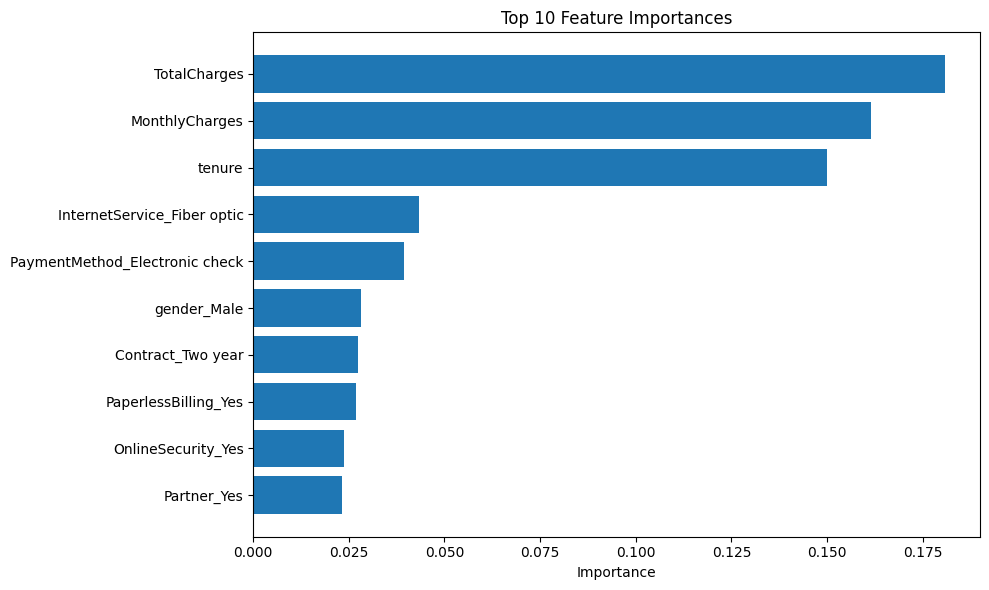

In [69]:
# Plots 10 features

top_features = feature_importance.head(10)

plt.figure(figsize=(10, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.gca().invert_yaxis()
plt.title("Top 10 Feature Importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig("../outputs/charts/churn_feature_importance.png")
plt.show()

In [60]:
# saves the feature importance result into the output folder

feature_importance.to_csv("../outputs/feature_importance.csv", index=False)

### Exports Data For DashBoard

In [61]:
# saves the cleaned dataset

df.to_csv("../outputs/cleaned_churn_data.csv", index=False)